In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

In [79]:
#connect to duckdb
con = duckdb.connect("../Data/duckdb/olist.duckdb")

#Load CSV & Create Views
con.read_csv("../Data/Processed/orders_clean.csv").create_view("orders");

### Order Status Analysis

In [80]:
# Calculate the total number of orders
total = con.sql(""" 
    select count(*) as total
    from orders
 """).df()

print(f"Total orders: {total.iloc[0, 0]}")

Total orders: 99441


In [81]:
#check order status of orders
order_status = con.sql(""" 
        select order_status,
                count(*) as status_number,
                count(*) * 100.0 / sum(count(*)) over () as status_percent
        from orders
        group by order_status
        order by status_number desc;
 """).df()

print("number of each order_status:")
display(order_status)

number of each order_status:


,order_status,status_number,status_percent
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


In [82]:
con.close()

In [83]:
#reconnect to duckdb
con = duckdb.connect("../Data/duckdb/olist.duckdb")

In [84]:
order_status

,order_status,status_number,status_percent
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


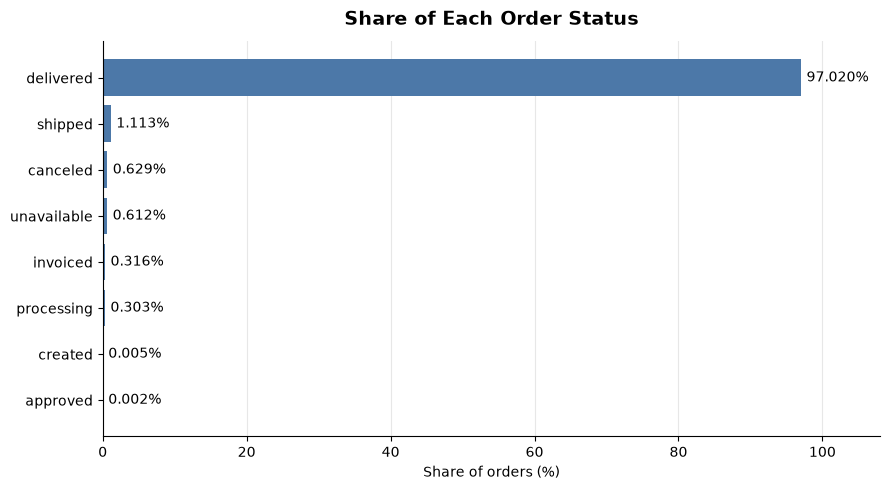

In [85]:
#visualizing chart
plot_df = order_status.sort_values("status_percent", ascending=True)  # ascending=True puts the largest bar on top

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(plot_df["order_status"], plot_df["status_percent"], color="#4C78A8")

ax.bar_label(bars, fmt="%.3f%%", padding=4, fontsize=10)

ax.set_title("Share of Each Order Status", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Share of orders (%)")
ax.set_ylabel("")
ax.set_xlim(0, 108)  # room so the 97.02% label isn't cut off
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Order Status Analysis – Conclusion

The Olist dataset contains **99,441 orders**, of which **97.02% (96,478)** were successfully delivered. Only **0.63%** were canceled, indicating a relatively low cancellation rate.

The remaining orders were distributed across other statuses, including shipped, unavailable, invoiced, and processing.

**Business Insight:**

Overall, Olist demonstrates a high order fulfillment rate and a relatively low cancellation rate. However, further investigation of non-delivered orders is needed to identify potential operational issues.

### Monthly Order Analysis & Yearly Comparison

In [86]:
monthly_order = con.sql(""" 
    select order_month,
            order_year,
            count(*) as orders_count
    from orders
    group by order_year, order_month
    order by order_year ,order_month
""").df()

# Real date column, so months sort and plot chronologically
monthly_order["month_start"] = pd.to_datetime(
    dict(year=monthly_order["order_year"], month=monthly_order["order_month"], day=1)
)

#set month abbreviation
monthly_order['month_abbr'] = monthly_order['month_start'].dt.strftime('%b')


print("number of orders for each month:")
display(monthly_order[["month_start","month_abbr","orders_count"]])


number of orders for each month:


,month_start,month_abbr,orders_count
0,2016-09-01,Sep,4
1,2016-10-01,Oct,324
2,2016-12-01,Dec,1
3,2017-01-01,Jan,800
4,2017-02-01,Feb,1780
5,2017-03-01,Mar,2682
6,2017-04-01,Apr,2404
7,2017-05-01,May,3700
8,2017-06-01,Jun,3245
9,2017-07-01,Jul,4026


In [87]:
# Valid analysis window 
START = pd.Timestamp("2017-01-01")
END   = pd.Timestamp("2018-08-01")   # last valid month (month-start date)

# Fill missing months (e.g. Nov 2016 has no row) with 0 so the line doesn't skip them
full_range = pd.date_range(monthly_order["month_start"].min(),
                           monthly_order["month_start"].max(), freq="MS")
timeline = (monthly_order.set_index("month_start")["orders_count"]
            .reindex(full_range, fill_value=0))

In [88]:
#valid range information
valid = timeline[START:END]

max_date, max_val = valid.idxmax(), valid.max()
min_date, min_val = valid.idxmin(), valid.min()

print("number of orders in valid range date:")
display(valid.to_frame())
print(f"month with the most orders  : {max_date.strftime('%B %Y')} with {max_val:,} orders")
print(f"month with the fewest orders: {min_date.strftime('%B %Y')} with {min_val:,} orders")


number of orders in valid range date:


,orders_count
2017-01-01,800
2017-02-01,1780
2017-03-01,2682
2017-04-01,2404
2017-05-01,3700
2017-06-01,3245
2017-07-01,4026
2017-08-01,4331
2017-09-01,4285
2017-10-01,4631


month with the most orders  : November 2017 with 7,544 orders
month with the fewest orders: January 2017 with 800 orders


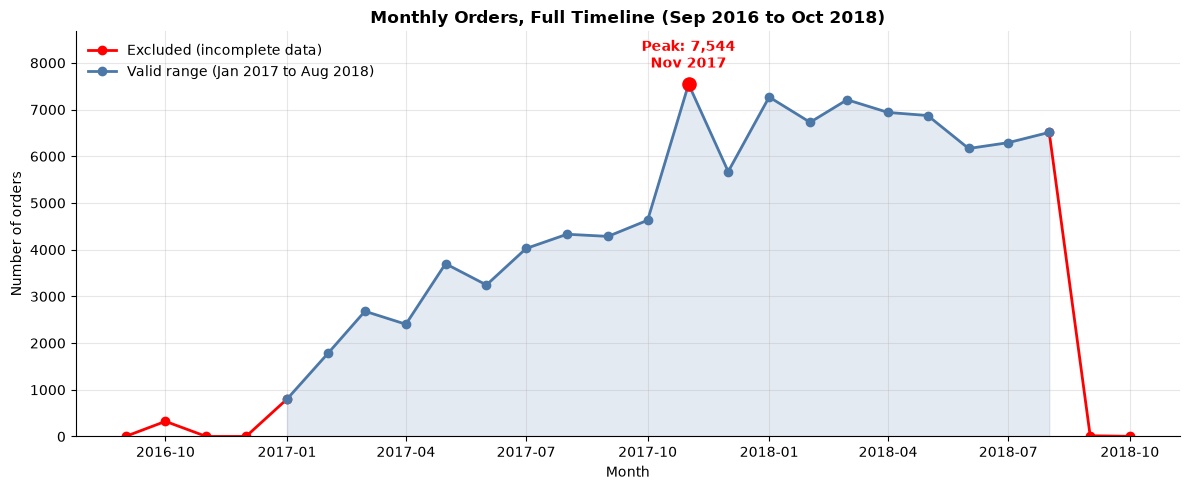

In [89]:
#Monthly Orders, Full Timeline chart
fig, ax = plt.subplots(figsize=(12, 5))

# Split the timeline into three parts
# (slicing is inclusive on both ends, so the boundary month is shared and the lines connect)
left_excluded  = timeline[:START]    # Sep 2016 to Jan 2017
valid          = timeline[START:END] # Jan 2017 to Aug 2018
right_excluded = timeline[END:]      # Aug 2018 to Oct 2018

# Excluded parts in red
ax.plot(left_excluded.index, left_excluded.values,
        marker="o", color="red", linewidth=2, label="Excluded (incomplete data)")
ax.plot(right_excluded.index, right_excluded.values,
        marker="o", color="red", linewidth=2)

# Valid window in blue, drawn on top so the shared boundary points stay blue
ax.plot(valid.index, valid.values,
        marker="o", color="#4C78A8", linewidth=2, zorder=3,
        label="Valid range (Jan 2017 to Aug 2018)")

# Light fill under the valid window only
ax.fill_between(valid.index, valid.values, color="#4C78A8", alpha=0.15)

# Peak inside the valid window
peak_date  = valid.idxmax()
peak_value = valid.max()
ax.scatter(peak_date, peak_value, color="red", s=90, zorder=5)
ax.annotate(f"Peak: {peak_value:,}\n{peak_date.strftime('%b %Y')}",
            xy=(peak_date, peak_value),
            xytext=(0, 12), textcoords="offset points",
            ha="center", color="red", fontweight="bold")

ax.set_ylim(0, timeline.max() * 1.15)
ax.set_title("Monthly Orders, Full Timeline (Sep 2016 to Oct 2018)", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
ax.grid(axis="y", alpha=0.3)
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

#### Monthly Orders: Conclusion

**Valid window:** Jan 2017 to Aug 2018. Sep to Dec 2016 (ramp-up, 329 orders in total) and Sep to Oct 2018 (data cutoff, 20 orders in total) are excluded because their incomplete coverage distorts the trend.

**Highest and lowest months (valid window)**
- Highest: **November 2017** with **7,544** orders.
- Lowest: **January 2017** with **800** orders. This is the start of the ramp-up, not a real low. After the growth phase, the lowest month is June 2018 (6,167).

**Trend**
- **Growth (Jan to Oct 2017):** orders rose from 800 to 4,631 (about 5.8x), with small dips in April and June that recovered the next month.
- **Step-up (Nov 2017):** orders jumped 63% in one month, the sharpest change in the data. This may be linked to Black Friday, but it is a hypothesis, since only one November is available.
- **Plateau (Dec 2017 to Aug 2018):** December fell to 5,673 but stayed above the pre-November level. From January 2018, orders stayed between about 6,200 and 7,300 per month, with a slight downward drift until June and a small recovery in July and August.

**Key takeaway:** The volume of orders grew strongly in 2017, and November 2017 looks like a permanent upward shift in the baseline rather than a one-time spike. Growth then stalled at a high, stable level through 2018.

**Limitations**
- Only one full year (2017) is available, so seasonality cannot be confirmed. Explanations such as Black Friday are hypotheses.
- Order count measures volume only, not revenue, profit, or customer satisfaction.
- Month lengths differ (e.g., February has 28 days), so small month-to-month differences should be read with caution.

In [90]:
# Valid analysis window 
START = pd.Timestamp("2017-01-01")
END   = pd.Timestamp("2018-08-01")   # last valid month (month-start date)

#monthly order per year in valid range
valid_range = monthly_order.loc[monthly_order["month_start"].between(START,END)]
display(valid_range[["month_start" , "order_year" ,"order_month","month_abbr" ,"orders_count"]])

,month_start,order_year,order_month,month_abbr,orders_count
3,2017-01-01,2017,1,Jan,800
4,2017-02-01,2017,2,Feb,1780
5,2017-03-01,2017,3,Mar,2682
6,2017-04-01,2017,4,Apr,2404
7,2017-05-01,2017,5,May,3700
8,2017-06-01,2017,6,Jun,3245
9,2017-07-01,2017,7,Jul,4026
10,2017-08-01,2017,8,Aug,4331
11,2017-09-01,2017,9,Sep,4285
12,2017-10-01,2017,10,Oct,4631


In [100]:
year_2017 = valid_range.loc[valid_range["order_year"] == 2017]

print("--- orders information in 2017 ---")
print("month with the most orders in 2017:" \
    f" {year_2017.loc[year_2017["orders_count"].idxmax(),"month_abbr"]}" \
     f" with {year_2017["orders_count"].max()} orders")
print("month with the least orders in 2017:" \
    f" {year_2017.loc[year_2017["orders_count"].idxmin(),"month_abbr"]}" \
     f" with {year_2017["orders_count"].min()} orders")



year_2018 = valid_range.loc[valid_range["order_year"] == 2018]

print("\n--- orders information in 2018 ---")
print("month with the most orders in 2018:" \
    f" {year_2018.loc[year_2018["orders_count"].idxmax(),"month_abbr"]}" \
     f" with {year_2018["orders_count"].max()} orders")
print("month with the least orders in 2018:" \
    f" {year_2018.loc[year_2018["orders_count"].idxmin(),"month_abbr"]}" \
     f" with {year_2018["orders_count"].min()} orders")


--- orders information in 2017 ---
month with the most orders in 2017: Nov with 7544 orders
month with the least orders in 2017: Jan with 800 orders

--- orders information in 2018 ---
month with the most orders in 2018: Jan with 7269 orders
month with the least orders in 2018: Jun with 6167 orders


In [98]:
#find top 5 month
top_5 = valid_range.sort_values(by="orders_count", ascending=False, ignore_index=True)

display(top_5.loc[:4,["order_year","month_abbr","orders_count"]]) 

,order_year,month_abbr,orders_count
0,2017,Nov,7544
1,2018,Jan,7269
2,2018,Mar,7211
3,2018,Apr,6939
4,2018,May,6873


In [107]:
valid = timeline[START:END]

# Month-over-month % change (first month is NaN, which is correct)
mom = valid.pct_change().mul(100).round(1)
mom_table = pd.DataFrame({"orders": valid, "mom_%": mom})

print("mom table:")
display(mom_table)


# YoY, same months only (Jan to Aug)
y17 = timeline["2017-01-01":"2017-08-01"]
y18 = timeline["2018-01-01":"2018-08-01"]
yoy = pd.DataFrame({"2017": y17.values, "2018": y18.values},
                   index=month_labels[:8])
yoy["yoy_%"] = ((yoy["2018"] / yoy["2017"] - 1) * 100).round(1)

print("yoy table :")
display(yoy)


print("Fair yearly comparison: same months only (Jan to Aug)")
jan_aug = valid[valid.index.month <= 8]
display(jan_aug.groupby(jan_aug.index.year).agg(["sum", "mean"]).round(0))

mom table:


,orders,mom_%
2017-01-01,800,NaN
2017-02-01,1780,122.5
2017-03-01,2682,50.7
2017-04-01,2404,-10.4
2017-05-01,3700,53.9
2017-06-01,3245,-12.3
2017-07-01,4026,24.1
2017-08-01,4331,7.6
2017-09-01,4285,-1.1
2017-10-01,4631,8.1


yoy table :


,2017,2018,yoy_%
month_abbr,,,
Jan,800,7269,808.6
Feb,1780,6728,278.0
Mar,2682,7211,168.9
Apr,2404,6939,188.6
May,3700,6873,85.8
Jun,3245,6167,90.0
Jul,4026,6292,56.3
Aug,4331,6512,50.4


Fair yearly comparison: same months only (Jan to Aug)


,sum,mean
2017,22968,2871.0
2018,53991,6749.0


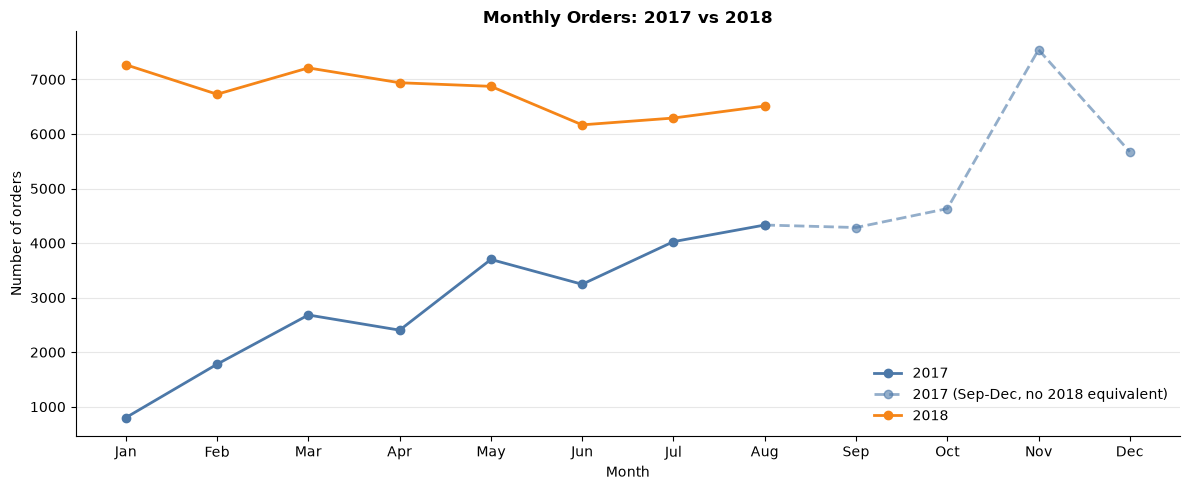

In [93]:
#comparable chart (year 2017 vs 2018)
# Pivot: rows = month number, columns = year
yoy = (monthly_order[monthly_order["order_year"].isin([2017, 2018])]
       .pivot(index="order_month", columns="order_year", values="orders_count"))

# 2018 is only valid through August
yoy_2018 = yoy[2018].where(yoy.index <= 8)

month_labels = valid_range.loc[valid_range["order_year"] == 2017,"month_abbr"]

fig, ax = plt.subplots(figsize=(12, 5))

# 2017: solid for Jan-Aug (comparable), dashed for Sep-Dec (context only)
ax.plot(yoy.index[:8], yoy[2017][:8], marker="o", color="#4C78A8", linewidth=2, label="2017")
ax.plot(yoy.index[7:], yoy[2017][7:], marker="o", color="#4C78A8", linewidth=2,
        linestyle="--", alpha=0.6, label="2017 (Sep-Dec, no 2018 equivalent)")

ax.plot(yoy.index[:8], yoy_2018[:8], marker="o", color="#F58518", linewidth=2, label="2018")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_title("Monthly Orders: 2017 vs 2018", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Number of orders")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Yearly and Monthly Comparison: Conclusion

**Question:** Has the store's activity increased over the period?

**Answer:** Yes, but the growth happened mainly in 2017 and flattened in 2018.

**Evidence**
- **Year over year (Jan to Aug, same months):** 2018 was higher than 2017 in all 8 months. The average rose from 2,871 to 6,749 orders per month (+135%).
- **The gap is shrinking:** the YoY increase fell from +809% (Jan) to +50% (Aug), because 2017 kept growing while 2018 stayed flat.
- **2017:** orders grew from 800 (Jan) to 4,631 (Oct), then jumped 63% in Nov (7,544). Increases outnumbered decreases (7 up, 4 down).
- **2018:** orders stayed between 6,167 and 7,269. Aug (6,512) is 10% below Jan (7,269). Ups and downs were even (4 and 4), with small MoM changes.
- **Top 5 months:** Nov 2017, Jan, Mar, Apr and May 2018 (1 from 2017, 4 from 2018), all within the later part of the window.

**Decision:** Order activity increased clearly over the dataset period, with a step-up around Nov 2017. After that, volume stabilized at about 6,200 to 7,300 orders per month, with a slight downward drift in 2018 rather than continued growth.

**Limitations**
- 2018 data is available only through August, so full-year totals and averages are not comparable between years.
- Only one full year exists, so seasonality can't be confirmed.
- Order count shows volume only, not revenue or customer satisfaction.